# Prototype F: PJM capacity prices and what they add to a monthly bill
**Question:** Grid strain is abstract. PJM, the grid operator for 13 states and DC, runs a yearly auction to buy enough power plant capacity for future peak demand. When forecast demand (much of it from data centers) grows faster than supply, the auction price rises and every utility in the region pays it. How big was the jump, and what does it mean for a household?

**Data:** PJM Base Residual Auction results for delivery years 2017/18 to 2027/28 (clearing price in $/MW-day, total cost, reserve margin), transcribed from the 2027/28 BRA report. PJM annual load and peak from EIA Form 930. Typical household usage from EIA Form 861.

**Design:** a step chart of the clearing price (each delivery year runs June to May, so the price is flat across it), with notes on key events, and a slider where you set your monthly kWh to see roughly what capacity costs add to your bill in each year.

**What this can show:** the size and timing of the jump, how close the grid is running to its reserve target, and a rough dollar figure for a household.
**What it can't:** an exact bill. The estimate is a simple average and real bills differ by utility (see caveats).

How the bill estimate works:
1. Capacity cost per kWh = total auction cost for the delivery year / PJM annual load (EIA-930, nearest complete year).
2. Monthly add = that cost per kWh x your monthly kWh.

Caveats carried onto the page:
- This spreads capacity cost evenly over every kWh used by every customer class. Households use more of their power at peak times than factories do, so their true share is likely higher.
- Utilities pass capacity costs through with lags and hedges, and some PJM utilities buy capacity outside the auction, so not every PJM customer saw the change on the same date or at the same size.
- The earliest complete year of PJM load in EIA-930 is 2019, so 2017/18 and 2018/19 use 2019 load, and 2026/27 and 2027/28 use 2025 load, the latest complete year.
- The chart shows the PJM-wide price. In 2025/26 the BGE (Baltimore) and Dominion zones cleared higher, at $466.35 and $444.26 per MW-day, so Maryland and Virginia households faced more than the chart shows.
- Auction dates, prices and the cap were checked on 2026-11-16 against PJM and S&P reporting (listed at the end). The Market Monitor's data center figures below come from its 2025 State of the Market report and FERC complaint as quoted in news and policy summaries; confirm them against the primary documents before quoting.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name in ("data", "jppolizzi", "pnidadavolu", "sgarimella") else Path.cwd()
sys.path[:0] = [str(ROOT / ".pylibs"), str(ROOT / "scripts")]
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
CLEAN = ROOT / "data" / "clean"

# Same palette as prototypes C and D.
INK, INK2, GRID, AXIS, SURF = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE, ORANGE, AQUA, YELLOW, NEUTRAL = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#a9a89f"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": INK2,
                     "ytick.color": INK2, "axes.titlecolor": INK, "figure.facecolor": SURF, "axes.facecolor": SURF})
p = pd.read_csv(CLEAN / "pjm_bra_rto_prices.csv")
e = pd.read_csv(CLEAN / "eia930_ba_annual.csv").query("ba == 'PJM' and complete_year").set_index("year")
u = pd.read_csv(CLEAN / "eia861_utility_sales.csv")

y0 = p.delivery_year_start
p["load_year"] = y0.clip(e.index.min(), e.index.max())
p["load_gwh"] = p.load_year.map(e.total_gwh_scaled)
p["cents_per_kwh"] = p.cleared_cost_usd_billion * 1e9 / (p.load_gwh * 1e6) * 100
r = u[(u.ba_code == "PJM") & (u.year == 2025)]
TYPICAL = r.res_mwh.sum() * 1000 / r.res_customers.sum() / 12
print(f"Typical PJM household (2025): {TYPICAL:.0f} kWh/month")
p["usd_month_typical"] = p.cents_per_kwh * TYPICAL / 100
display(p[["delivery_year", "rto_clearing_price_usd_per_mw_day", "cleared_cost_usd_billion", "rpm_reserve_margin_pct",
           "load_gwh", "cents_per_kwh", "usd_month_typical"]].round(2))
print("PJM peak load (EIA-930):", e.peak_mw.astype(int).to_dict())

Typical PJM household (2025): 849 kWh/month


,delivery_year,rto_clearing_price_usd_per_mw_day,cleared_cost_usd_billion,rpm_reserve_margin_pct,load_gwh,cents_per_kwh,usd_month_typical
0,2017/18,120.00,7.5,20.1,800260.00,0.94,7.96
1,2018/19,164.77,10.9,20.2,800260.00,1.36,11.56
2,2019/20,100.00,7.0,22.9,800260.00,0.87,7.43
3,2020/21,76.53,7.0,23.9,770273.03,0.91,7.72
4,2021/22,140.00,9.3,22.0,796161.00,1.17,9.92
5,2022/23,50.00,3.9,21.1,810260.60,0.48,4.09
6,2023/24,34.13,2.2,21.6,784953.10,0.28,2.38
7,2024/25,28.92,2.2,21.7,815086.75,0.27,2.29
8,2025/26,269.92,14.7,18.6,843212.93,1.74,14.80
9,2026/27,329.17,16.1,18.9,843212.93,1.91,16.21


PJM peak load (EIA-930): {2019: 152315, 2020: 145428, 2021: 149590, 2022: 148528, 2023: 147605, 2024: 153121, 2025: 160560}


## Key numbers

In [2]:
a, b = p.set_index("delivery_year").loc["2024/25"], p.set_index("delivery_year").loc["2025/26"]
last = p.iloc[-1]
print(f"2024/25 to 2025/26: {a.rto_clearing_price_usd_per_mw_day:.2f} to {b.rto_clearing_price_usd_per_mw_day:.2f} $/MW-day "
      f"({b.rto_clearing_price_usd_per_mw_day / a.rto_clearing_price_usd_per_mw_day:.1f}x), total cost {a.cleared_cost_usd_billion} to {b.cleared_cost_usd_billion} $B")
print(f"Typical household: about ${a.usd_month_typical:.2f} to ${b.usd_month_typical:.2f} a month ({b.usd_month_typical - a.usd_month_typical:+.2f})")
print(f"Reserve margin: {p.rpm_reserve_margin_pct.max():.1f}% at its high, {last.rpm_reserve_margin_pct:.1f}% for {last.delivery_year}")
print(f"PJM peak load rose from {e.peak_mw.min():,.0f} MW ({e.peak_mw.idxmin()}) to {e.peak_mw.iloc[-1]:,.0f} MW ({e.index[-1]})")

2024/25 to 2025/26: 28.92 to 269.92 $/MW-day (9.3x), total cost 2.2 to 14.7 $B
Typical household: about $2.29 to $14.80 a month (+12.51)
Reserve margin: 23.9% at its high, 14.4% for 2027/28
PJM peak load rose from 145,428 MW (2020) to 160,560 MW (2025)


## Static figure for the proposal (saved as an image)

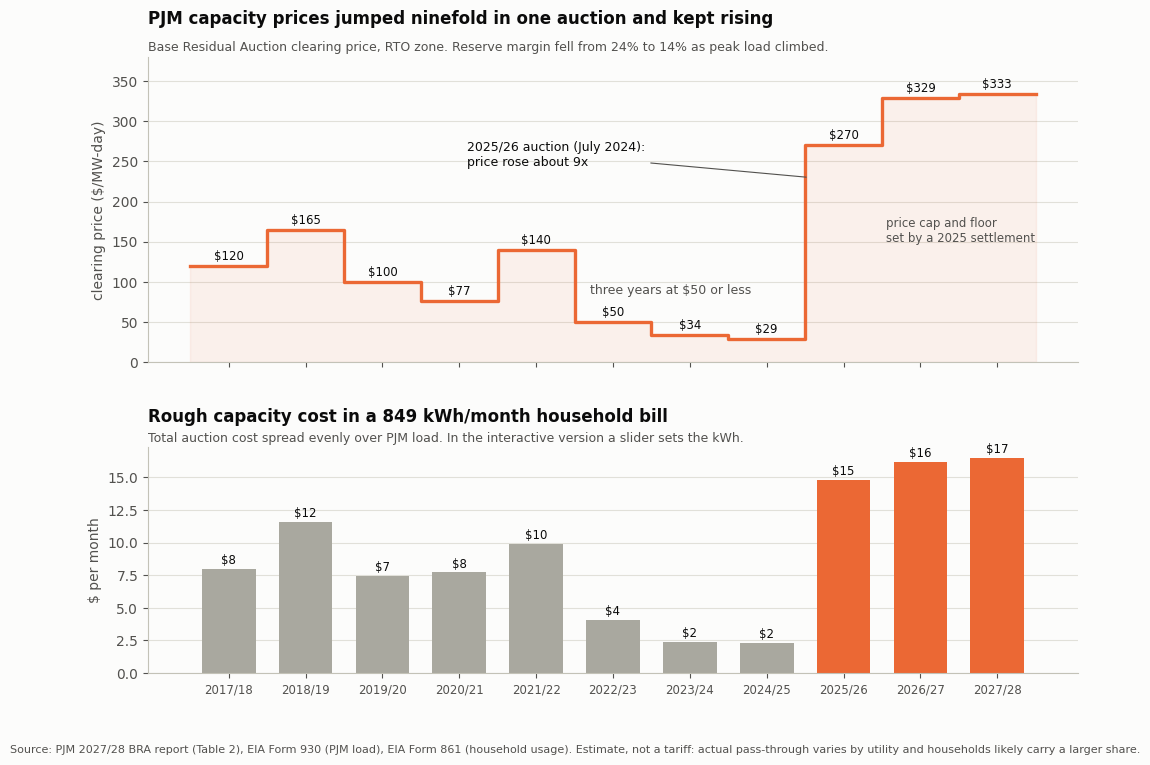

In [3]:
x = p.delivery_year_start.values
fig, (ax, bx) = plt.subplots(2, 1, figsize=(12, 8), sharex=True, gridspec_kw=dict(height_ratios=[1.35, 1], hspace=0.32))
xs = np.append(x, x[-1] + 1); ys = np.append(p.rto_clearing_price_usd_per_mw_day.values, p.rto_clearing_price_usd_per_mw_day.values[-1])
ax.step(xs, ys, where="post", color=ORANGE, lw=2.4)
ax.fill_between(xs, ys, step="post", color=ORANGE, alpha=0.08)
for xi, v in zip(x, p.rto_clearing_price_usd_per_mw_day):
    ax.text(xi + 0.5, v + 8, f"${v:,.0f}", ha="center", fontsize=8.5, color=INK)
ax.annotate("2025/26 auction (July 2024):\nprice rose about 9x", (2025.05, 230), xytext=(2020.6, 245), fontsize=9, color=INK,
            arrowprops=dict(arrowstyle="-", color=INK2, lw=0.8))
ax.text(2026.05, 150, "price cap and floor\nset by a 2025 settlement", fontsize=8.5, color=INK2)
ax.text(2022.2, 85, "three years at $50 or less", fontsize=9, color=INK2)
ax.set_ylim(0, 380); ax.set_ylabel("clearing price ($/MW-day)")
ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
for sp in ["top", "right"]: ax.spines[sp].set_visible(False)
ax.set_title("PJM capacity prices jumped ninefold in one auction and kept rising", loc="left", fontsize=12, fontweight="bold", pad=24)
ax.text(0, 1.01, f"Base Residual Auction clearing price, RTO zone. Reserve margin fell from {p.rpm_reserve_margin_pct.max():.0f}% "
        f"to {p.rpm_reserve_margin_pct.iloc[-1]:.0f}% as peak load climbed.", transform=ax.transAxes, fontsize=9, color=INK2, va="bottom")

bx.bar(x + 0.5, p.usd_month_typical, width=0.7, color=[NEUTRAL if v < 2025 else ORANGE for v in x])
for xi, v in zip(x, p.usd_month_typical):
    bx.text(xi + 0.5, v + 0.4, f"${v:.0f}", ha="center", fontsize=8.5, color=INK)
bx.set_ylabel("$ per month")
bx.set_xticks(x + 0.5, p.delivery_year, rotation=0, fontsize=8.5)
bx.grid(axis="y", color=GRID, lw=0.8); bx.set_axisbelow(True)
for sp in ["top", "right"]: bx.spines[sp].set_visible(False)
bx.set_title(f"Rough capacity cost in a {TYPICAL:.0f} kWh/month household bill", loc="left", fontsize=12, fontweight="bold", pad=18)
bx.text(0, 1.01, "Total auction cost spread evenly over PJM load. In the interactive version a slider sets the kWh.",
        transform=bx.transAxes, fontsize=9, color=INK2, va="bottom")
fig.text(0.01, 0.01, "Source: PJM 2027/28 BRA report (Table 2), EIA Form 930 (PJM load), EIA Form 861 (household usage). "
         "Estimate, not a tariff: actual pass-through varies by utility and households likely carry a larger share.", fontsize=8, color=INK2)
fig.savefig(ROOT / "images" / "prototype_f_capacity_bill.png", dpi=160, bbox_inches="tight")
plt.show()

## Interactive prototype (usage slider)
Drag the slider to set your monthly usage. The bars and the headline update to show roughly what capacity costs add to a bill at that usage in each delivery year. Hover the step chart for reserve margin and cleared capacity.
Saved as `sgarimella/prototype_f_capacity_bill.html`.

In [4]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

lab = p.delivery_year.tolist()
fig = make_subplots(rows=2, cols=1, shared_xaxes=True, row_heights=[0.58, 0.42], vertical_spacing=0.1,
                    subplot_titles=("Capacity auction clearing price ($/MW-day)", "What it adds to your monthly bill (rough estimate)"))
fig.add_trace(go.Scatter(x=list(xs), y=list(ys), mode="lines", line=dict(color=ORANGE, width=3, shape="hv"),
                         fill="tozeroy", fillcolor="rgba(235,104,52,0.08)", hoverinfo="skip", showlegend=False), 1, 1)
fig.add_trace(go.Scatter(x=(x + 0.5).tolist(), y=p.rto_clearing_price_usd_per_mw_day.tolist(), mode="markers+text",
    text=[f"${v:,.0f}" for v in p.rto_clearing_price_usd_per_mw_day], textposition="top center", marker=dict(size=7, color=ORANGE),
    customdata=p[["delivery_year", "rpm_reserve_margin_pct", "cleared_ucap_mw", "cleared_cost_usd_billion"]].values.tolist(),
    hovertemplate="<b>%{customdata[0]}</b><br>$%{y:,.2f}/MW-day<br>reserve margin %{customdata[1]}%<br>"
                  "%{customdata[2]:,.0f} MW cleared, $%{customdata[3]}B total<extra></extra>", showlegend=False), 1, 1)

def month(kwh):
    return (p.cents_per_kwh * kwh / 100).round(2).tolist()
def headline(kwh):
    m = p.cents_per_kwh * kwh / 100
    return (f"At {kwh:,} kWh a month, capacity costs went from about ${m.iloc[7]:.0f} (2024/25) "
            f"to ${m.iloc[8]:.0f} (2025/26) and ${m.iloc[-1]:.0f} (2027/28) a month")
start = int(round(TYPICAL / 50) * 50)
fig.add_trace(go.Bar(x=(x + 0.5).tolist(), y=month(start), text=[f"${v:.0f}" for v in month(start)], textposition="outside",
                     marker_color=[NEUTRAL if v < 2025 else ORANGE for v in x], hovertemplate="%{x}: $%{y:.2f}/month<extra></extra>",
                     showlegend=False), 2, 1)
BAR = len(fig.data) - 1
steps = []
for kwh in range(200, 2050, 50):
    steps.append(dict(label=f"{kwh}", method="update",
                      args=[{"y": [month(kwh)], "text": [[f"${v:.0f}" for v in month(kwh)]]}, {"title.text": headline(kwh)}, [BAR]]))
fig.add_annotation(x=2027.95, y=150, text="price cap and floor set by a 2025 settlement", showarrow=False, xanchor="right", font=dict(size=10, color=INK2), row=1, col=1)
fig.add_annotation(x=2025.05, y=250, ax=-120, ay=-10, text="2025/26 auction (July 2024): about 9x", font=dict(size=11), row=1, col=1)
fig.add_annotation(x=2023.5, y=95, text="three years at $50 or less", showarrow=False, font=dict(size=10, color=INK2), row=1, col=1)
fig.update_xaxes(tickvals=(x + 0.5).tolist(), ticktext=lab, range=[2017, 2028], gridcolor=GRID)
fig.update_yaxes(range=[0, 390], gridcolor=GRID, row=1, col=1)
fig.update_yaxes(title="$ per month", gridcolor=GRID, rangemode="tozero", row=2, col=1)
fig.update_layout(height=720, paper_bgcolor=SURF, plot_bgcolor=SURF, margin=dict(l=60, r=30, t=90, b=170),
                  title=dict(text=headline(start), x=0.01, font=dict(size=15)),
                  sliders=[dict(active=[s["label"] for s in steps].index(str(start)), y=-0.06, x=0.0, len=1.0,
                                currentvalue=dict(prefix="Your monthly usage (kWh): "), steps=steps)])
fig.add_annotation(text=f"Typical PJM household uses about {TYPICAL:.0f} kWh/month (EIA-861, 2025). Estimate spreads total auction cost "
                        "over all PJM load; real pass-through varies by utility.",
                   xref="paper", yref="paper", x=0, y=-0.3, showarrow=False, font=dict(size=10, color=INK2), xanchor="left")
fig.write_html(ROOT / "sgarimella" / "prototype_f_capacity_bill.html", include_plotlyjs=True, config={"displayModeBar": False})
fig.show()

## Reading so far
- Capacity prices sat at $50/MW-day or less for three years, then jumped about ninefold (from $28.92 to $269.92) in the 2025/26 auction and rose again to about $330 in the next two.
- The reserve margin in the auction results fell from the low 20s to about 14% for 2027/28 while PJM peak load rose. That is the grid strain residents describe, in the grid operator's own numbers.
- For a typical PJM household (about 850 kWh a month) the rough estimate goes from about $2 a month in 2024/25 to about $15 in 2025/26, roughly $12 more. Part of the jump is a return from unusually low years: before 2022/23 the same estimate ran $7 to $12 a month.

Event notes, checked 2026-11-16:
- The 2025/26 auction results came out on July 30, 2024: $269.92 per MW-day, 9.3 times the $28.92 of 2024/25, with 135,684 MW procured (PJM news release; S&P Global).
- FERC approved the price cap and floor on April 28, 2025, after a settlement push led by Pennsylvania's governor. The figures usually quoted are about $325 and $175 per MW-day. The tariff files them on a different capacity basis ($256.75 and $138.25, a 79% conversion), which is why the 2026/27 clearing price is $329.17 and not $325. At first the cap covered only the 2026/27 and 2027/28 auctions; later reporting says it was extended to 2028/29 and 2029/30. The repo's source note says through 2028/29.
- 2026/27 and 2027/28 both cleared at the cap (S&P Global; Calpine). The $333.44 for 2027/28 comes from the repo table and was not separately confirmed.
- Why the price rose: PJM said supply and demand were tightening, and its peak load forecast for 2025/26 rose from 150,640 MW to 153,883 MW. PJM's Independent Market Monitor puts most of the later cost on data centers: including existing and forecast data center load added about $7.3 billion (82.1%) to 2026/27 capacity revenue, and about $23.1 billion across the 2025/26, 2026/27 and 2027/28 auctions. IEEFA reports the Monitor attributed 63% of the 2025/26 price increase to data centers (one source, not yet matched to the Monitor's own text). The Monitor also estimates the cap and floor reduced capacity costs by about $13.1 billion over the two auctions where it applied.
- What this means for the story: the Monitor's numbers are a model of what prices would have been without data center load, not a direct count. They support linking data centers to the PJM jump, but plant retirements and market rule changes also matter, so the page should say "the Market Monitor attributes" and not "data centers caused".

Sources: PJM Inside Lines (2025/26 auction release; FERC collar approval), S&P Global (2025/26 and 2026/27 results), PJM Members Committee slides of 2025-02-07 (cap and floor basis), Calpine (2027/28 result), Monitoring Analytics 2025 State of the Market report and IMM FERC complaint (as quoted by APPA, IEEFA and Utility Dive).

Next steps: show the data center share of PJM's load forecast if we can get the forecast tables, and compare a few utilities' actual capacity line items against this estimate.